# EGN 321 — Module 6 Assignment 6.1
## SQLite History Builder
**Juan Pablo Osorio**

Primary evidence: the student's Module 5 NTC temperature CSV. Sampling interval: **1 second**, confirmed by the student. Timestamps are reconstructed for classroom replay. A separate instructor temperature dataset demonstrates absent-record gaps at **60-second** cadence.

Run all cells in order. Locally, extract the project ZIP and open this notebook in its project folder. In Google Colab, run the setup cell and upload the complete project ZIP when prompted. Ollama is optional and is not needed for any result.

In [1]:
from pathlib import Path
import os, sys, zipfile
if not Path('history_builder.py').exists():
    if Path('EGN321_Assignment6_1/history_builder.py').exists():
        os.chdir('EGN321_Assignment6_1')
    else:
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError('Extract the project ZIP and run the notebook from EGN321_Assignment6_1.')
        uploaded = files.upload()
        archive = next((name for name in uploaded if name.lower().endswith('.zip')), None)
        if archive is None:
            raise ValueError('Upload the complete assignment ZIP.')
        destination = Path.cwd().resolve()
        with zipfile.ZipFile(archive) as z:
            for name in z.namelist():
                candidate = (destination / name).resolve()
                if not candidate.is_relative_to(destination):
                    raise ValueError('Unsafe archive path')
            z.extractall(destination)
        os.chdir('EGN321_Assignment6_1')
sys.path.insert(0, str(Path.cwd()))
import history_builder as hb
import json, sqlite3, inspect, unittest
from IPython.display import display, Image
print('Project loaded. Student cadence:', hb.INTERVAL_SECONDS, 'second')

Project loaded. Student cadence: 1 second


## 1. Source, validation and replay clock
The two runs have separate sample counters. Preserve `run_id` and `sample_number`; the second run is placed after the first solely for classroom replay. The real inter-run delay is unknown. No line or gap calculation crosses the run boundary.

Accept finite Celsius values in 0–50 °C inclusive. A jump over 20 °C is a warning, not automatic rejection, preserving Module 5 behavior. Missing and rejected values remain NULL in `accepted_value`. Raw text, raw ADC and source status remain available.

In [2]:
primary_rows = hb.read_primary(hb.ROOT / 'data/readings_failure_scenario.csv')
print('Records:', len(primary_rows))
print('Replay clock:', primary_rows[0]['timestamp'], 'to', primary_rows[-1]['timestamp'])
print(json.dumps([primary_rows[0], primary_rows[61], primary_rows[109]], indent=2))

Records: 125
Replay clock: 2026-10-01T12:00:00 to 2026-10-01T12:02:04
[
  {
    "record_id": 1,
    "run_id": 1,
    "sample_number": 1,
    "timestamp": "2026-10-01T12:00:00",
    "sensor_name": "NTC_temperature",
    "raw_value": 25.0,
    "raw_text": "25.0",
    "raw_adc": "512",
    "accepted_value": 25.0,
    "status": "OK",
    "source_status": "OK",
    "source_filter_decision": "ACCEPT",
    "spike_flag": 0,
    "unit": "C",
    "timestamp_source": "reconstructed_for_classroom_replay",
    "failure_injected": 0
  },
  {
    "record_id": 62,
    "run_id": 1,
    "sample_number": 62,
    "timestamp": "2026-10-01T12:01:01",
    "sensor_name": "NTC_temperature",
    "raw_value": 54.1,
    "raw_text": "54.1",
    "raw_adc": "241",
    "accepted_value": null,
    "status": "OUT_OF_RANGE",
    "source_status": "OUT_OF_RANGE",
    "source_filter_decision": "REJECT_RANGE",
    "spike_flag": 1,
    "unit": "C",
    "timestamp_source": "reconstructed_for_classroom_replay",
    "failure_in

## 2. SQLite schema and deterministic analysis
Each run of the builder transactionally refreshes its own output database. The supplemental database is separate.

In [3]:
print(hb.SCHEMA)
primary, supplemental = hb.main()


CREATE TABLE IF NOT EXISTS metadata (key TEXT PRIMARY KEY, value TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS sensor_readings (
 record_id INTEGER PRIMARY KEY,
 run_id INTEGER NOT NULL,
 sample_number INTEGER NOT NULL,
 timestamp TEXT NOT NULL,
 sensor_name TEXT NOT NULL,
 raw_value REAL,
 raw_text TEXT NOT NULL,
 raw_adc TEXT,
 accepted_value REAL,
 status TEXT NOT NULL,
 source_status TEXT NOT NULL,
 source_filter_decision TEXT NOT NULL,
 spike_flag INTEGER NOT NULL CHECK (spike_flag IN (0,1)),
 unit TEXT NOT NULL,
 timestamp_source TEXT NOT NULL,
 failure_injected INTEGER NOT NULL CHECK (failure_injected IN (0,1)),
 UNIQUE (sensor_name, run_id, sample_number),
 UNIQUE (sensor_name, timestamp),
 CHECK (accepted_value IS NULL OR status IN ('OK','SUSPICIOUS'))
);
CREATE INDEX IF NOT EXISTS idx_sensor_time ON sensor_readings(sensor_name,timestamp);
CREATE INDEX IF NOT EXISTS idx_time ON sensor_readings(timestamp);



{
  "primary": {
    "received_records": 125,
    "expected_records_within_observed_runs": 125,
    "missing_records": 0,
    "records_with_missing_values": 1,
    "numeric_readings": 124,
    "accepted_readings": 105,
    "record_completeness_percent": 100.0,
    "numeric_completeness_percent": 99.2,
    "accepted_completeness_percent": 84.0,
    "status_counts": {
      "MISSING": 1,
      "OK": 103,
      "OUT_OF_RANGE": 19,
      "SUSPICIOUS": 2
    },
    "gap_count": 0,
    "largest_record_gap_seconds": 0,
    "first_timestamp": "2026-10-01T12:00:00",
    "latest_timestamp": "2026-10-01T12:02:04",
    "accepted_min_c": 14.0,
    "accepted_max_c": 36.0,
    "accepted_median_c": 27.0
  },
  "instructor_supplement": {
    "received_records": 1756,
    "expected_records_within_observed_runs": 1801,
    "missing_records": 45,
    "records_with_missing_values": 0,
    "numeric_readings": 1756,
    "accepted_readings": 1753,
    "record_completeness_percent": 97.50138811771238,
    "num

## 3. Queries anchored to the latest stored timestamp
The SQL uses inclusive endpoints `[latest − duration, latest]`. Completeness counts only the observed interval inside each run. An unobserved hour or day before the dataset starts is not assumed to be a sensor outage.

In [4]:
print(inspect.getsource(hb.query_history))
db = hb.ROOT / 'results/primary/module6_sensor_history.db'
for label, hours in [('Last hour', 1), ('Last day', 24), ('Full history', None)]:
    queried = hb.query_history(db, hours)
    print(label, json.dumps(hb.summarize(queried, 1), indent=2))

def query_history(path, hours=None):
    """Inclusive windows [latest-duration, latest], anchored to stored data."""
    with sqlite3.connect(path) as conn:
        conn.row_factory = sqlite3.Row
        latest = conn.execute("SELECT MAX(timestamp) FROM sensor_readings").fetchone()[0]
        if latest is None:
            return []
        if hours is None:
            result = conn.execute("SELECT * FROM sensor_readings ORDER BY timestamp,sensor_name")
        else:
            if hours < 0:
                raise ValueError("Window duration cannot be negative")
            cutoff = (parse_time(latest)-timedelta(hours=hours)).isoformat()
            result = conn.execute("SELECT * FROM sensor_readings WHERE timestamp >= ? "
                                  "AND timestamp <= ? ORDER BY timestamp,sensor_name",
                                  (cutoff,latest))
        return [dict(r) for r in result]

Last hour {
  "received_records": 125,
  "expected_records_within_observed_runs": 125

## 4. Completeness and gap detection
A timestamp separation greater than the declared interval is a record gap. Missing slots equal `separation / interval − 1`. Grid misalignment and duplicate timestamps cause an error rather than a silent estimate.

The primary history has 125 logged records but only 124 numeric measurements and 105 accepted values. Its missing measurement at record 110 is not an absent database row. Record completeness is 100%, numeric completeness is 99.2%, and accepted-value completeness is 84%. These percentages concern the reconstructed observed runs, not continuous real-world uptime.

In [5]:
print(inspect.getsource(hb.detect_gaps))
print('Primary record gaps:', primary['gaps'])
print('Instructor record gaps:', json.dumps(supplemental['gaps'], indent=2))

def detect_gaps(rows, interval):
    """Detect absent records within each run; reject duplicate/off-grid times.

    largest gap is the elapsed time between bounding records, not the number
    of missing positions. At 1 s cadence a 3 s separation means 2 missing slots.
    """
    if interval <= 0:
        raise ValueError("Sampling interval must be positive")
    gaps = []
    for g in groups(rows):
        for a,b in zip(g,g[1:]):
            delta = (parse_time(b["timestamp"])-parse_time(a["timestamp"])).total_seconds()
            ratio = delta/interval
            if delta <= 0 or not math.isclose(ratio,round(ratio),abs_tol=1e-7):
                raise ValueError("Timestamps must be unique and on the declared sampling grid")
            if delta > interval + 1e-7:
                gaps.append({"sensor_name":a["sensor_name"],"run_id":a["run_id"],
                    "before":a["timestamp"],"after":b["timestamp"],
                    "elapsed_seconds":delta,"missing_slots":round(rat

## 5. Primary plots
Lines stop at null accepted values and at run boundaries. Rejected raw temperatures are shown separately; they are never replaced with zero.

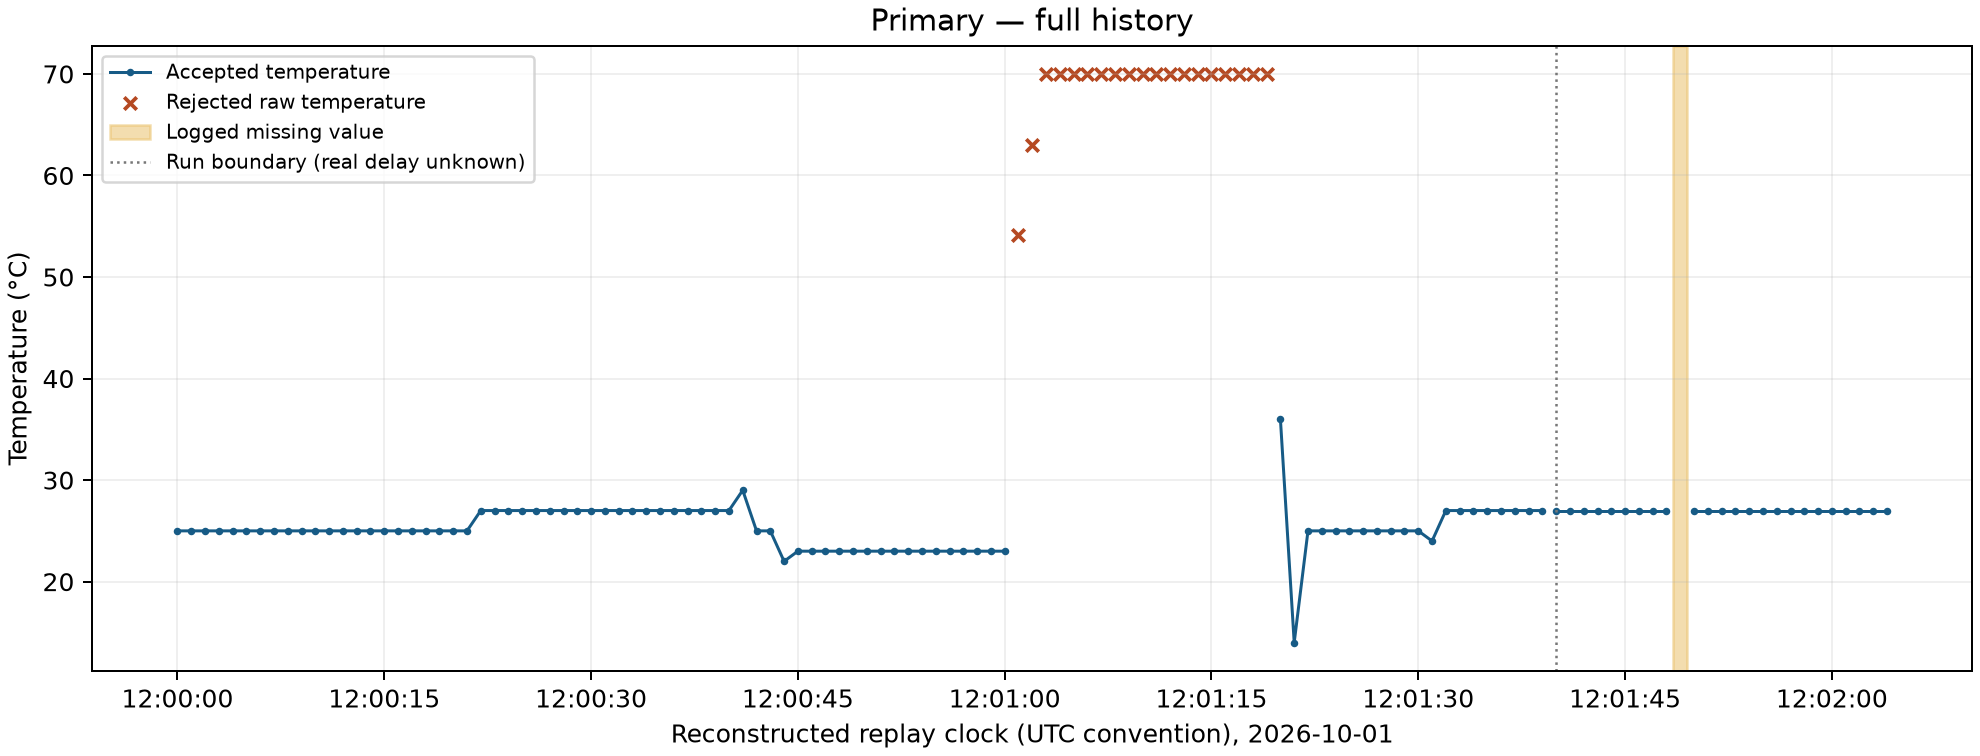

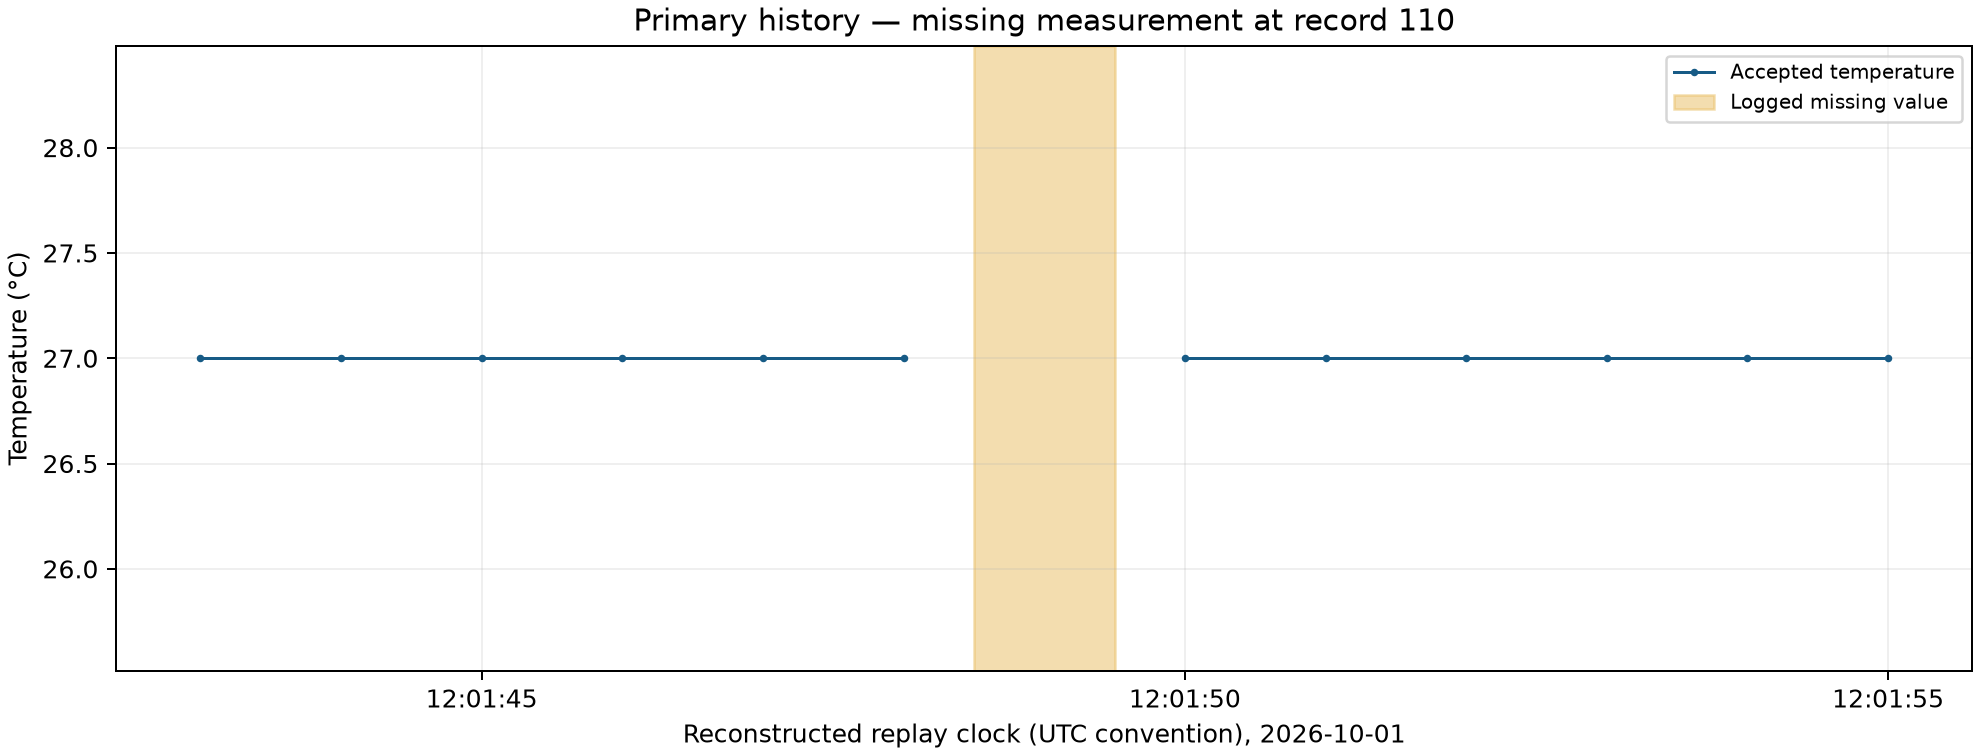

In [6]:
display(Image(filename='results/primary/full_history.png'))
display(Image(filename='results/primary/missing_value_detail.png'))

## 6. Instructor supplement — actual missing timestamp positions
This is the supplied practice dataset, not a new student sensor run. Temperature is the only sensor selected from its five-sensor CSV. The source timestamps have no timezone; no timezone is inferred. At 60-second cadence, the observed 30-hour span has 1,801 expected and 1,756 received records. The 45 absent records occur in two gaps. A 26-minute separation bounds 25 missing one-minute positions, not 26 missing readings.

last_hour {
  "received_records": 61,
  "expected_records_within_observed_runs": 61,
  "missing_records": 0,
  "records_with_missing_values": 0,
  "numeric_readings": 61,
  "accepted_readings": 61,
  "record_completeness_percent": 100.0,
  "numeric_completeness_percent": 100.0,
  "accepted_completeness_percent": 100.0,
  "status_counts": {
    "OK": 61
  },
  "gap_count": 0,
  "largest_record_gap_seconds": 0,
  "first_timestamp": "2026-10-02T13:00:00",
  "latest_timestamp": "2026-10-02T14:00:00",
  "accepted_min_c": 23.7,
  "accepted_max_c": 24.62,
  "accepted_median_c": 24.16
}
last_day {
  "received_records": 1421,
  "expected_records_within_observed_runs": 1441,
  "missing_records": 20,
  "records_with_missing_values": 0,
  "numeric_readings": 1421,
  "accepted_readings": 1419,
  "record_completeness_percent": 98.6120749479528,
  "numeric_completeness_percent": 98.6120749479528,
  "accepted_completeness_percent": 98.47328244274809,
  "status_counts": {
    "OK": 1419,
    "OUT_OF_RA

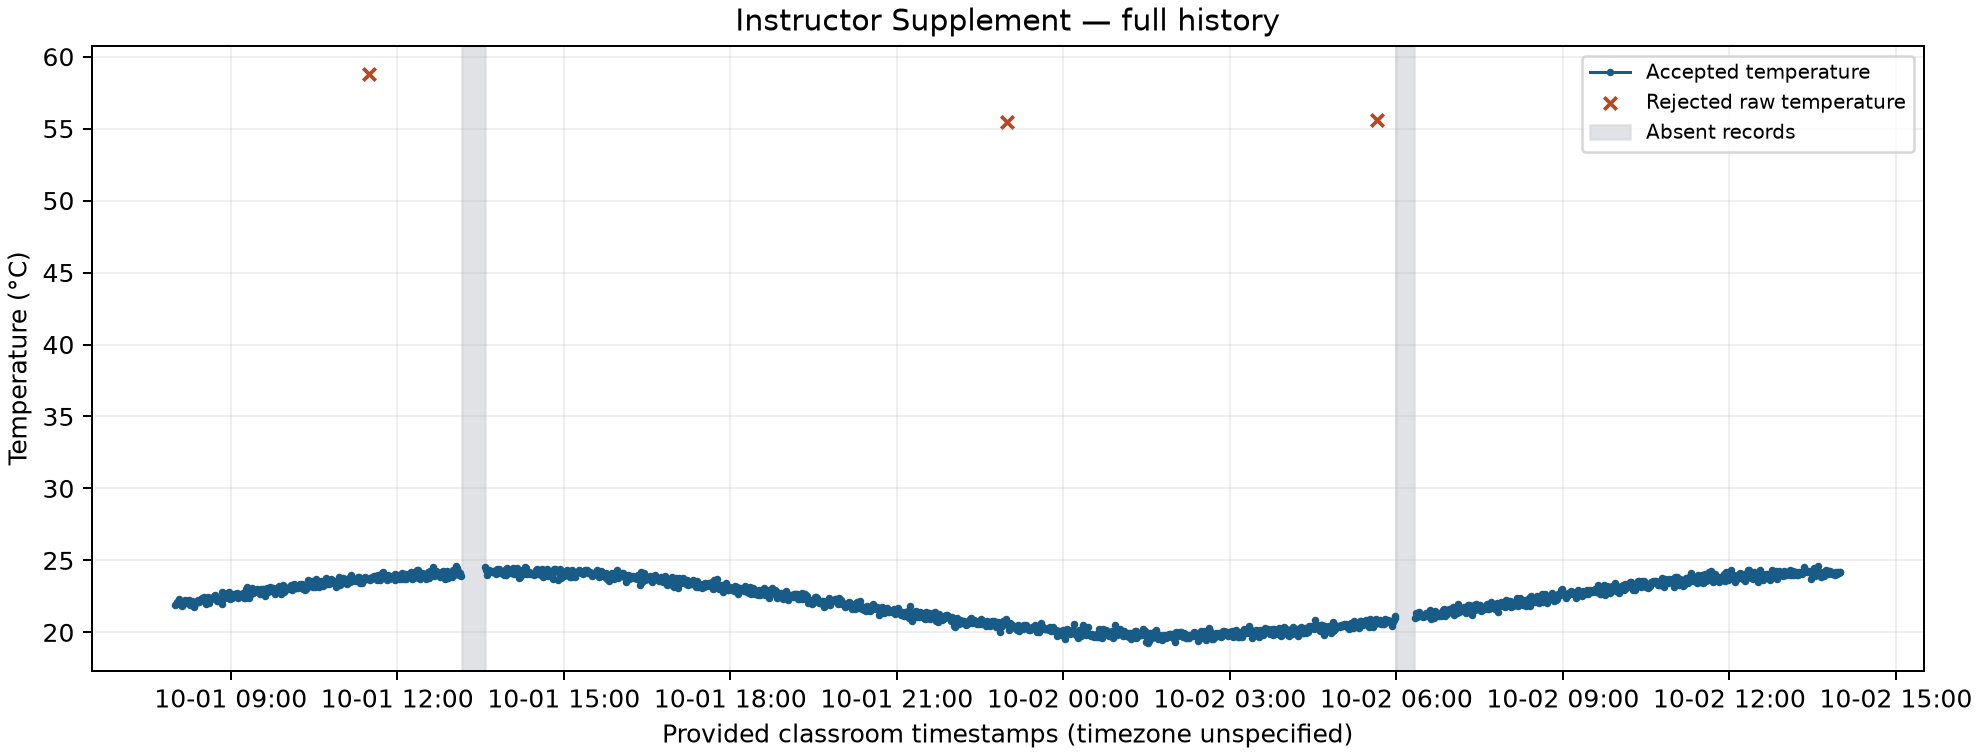

In [7]:
for window, summary in supplemental['windows'].items():
    print(window, json.dumps(summary, indent=2))
display(Image(filename='results/instructor_supplement/full_history.png'))

## 7. Automated tests
Tests exercise database round trips, rollback, repeat imports, known missing slots, missing measurements, query boundaries, sampling-grid errors, and plot segment boundaries. Test-only fixtures never enter the submitted evidence database.

In [8]:
import test_history_builder
suite = unittest.defaultTestLoader.loadTestsFromModule(test_history_builder)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful(), 'At least one automated test failed.' 

test_duplicate_import_rolls_back (test_history_builder.HistoryTests.test_duplicate_import_rolls_back) ... 

ok


test_gap_counts_missing_positions_not_elapsed_seconds (test_history_builder.HistoryTests.test_gap_counts_missing_positions_not_elapsed_seconds) ... 

ok


test_instructor_evidence_has_45_missing_positions (test_history_builder.HistoryTests.test_instructor_evidence_has_45_missing_positions) ... 

...

test_unknown_inter_run_delay_is_not_counted (test_history_builder.HistoryTests.test_unknown_inter_run_delay_is_not_counted) ... 

ok


test_windows_use_latest_timestamp_and_inclusive_cutoff (test_history_builder.HistoryTests.test_windows_use_latest_timestamp_and_inclusive_cutoff) ... 

ok


----------------------------------------------------------------------
Ran 12 tests in 0.026s

OK


## 8. Supported conclusions and limits
The primary data supports a description of the recorded replay sequence and the validation decisions. It does not establish acquisition dates, the duration between runs, continuous-hour/day behavior, calibration accuracy, or the temperature at the missing sample. The values on each side of record 110 are 27 °C, but the missing value remains unknown.

The instructor history shows changes in recorded temperature on each side of two missing periods. It does not establish what happened inside those periods or a physical cause. Median, minimum and maximum describe available accepted samples only; no interpolation, imputation or averaging across a gap is used.

AI assistance was used for implementation and writing. All reported quantities come from executed Python/SQLite analysis. Ollama was not run and no Ollama output is claimed.

In [9]:
print('Deliverables:')
for path in sorted(Path('results').rglob('*')):
    if path.is_file():
        print(path.as_posix())

Deliverables:
results/instructor_supplement/analysis.json
results/instructor_supplement/full_history.png
results/instructor_supplement/full_history_report.csv
results/instructor_supplement/gap_completeness_report.csv
results/instructor_supplement/gaps.csv
results/instructor_supplement/last_day.png
results/instructor_supplement/last_day_report.csv
results/instructor_supplement/last_hour.png
results/instructor_supplement/last_hour_report.csv
results/instructor_supplement/module6_sensor_history.db
results/primary/analysis.json
results/primary/full_history.png
results/primary/full_history_report.csv
results/primary/gap_completeness_report.csv
results/primary/gaps.csv
results/primary/last_day.png
results/primary/last_day_report.csv
results/primary/last_hour.png
results/primary/last_hour_report.csv
results/primary/missing_value_detail.png
results/primary/module6_sensor_history.db
results/test_results.txt
